# NutriScan CO · Análisis exploratorio (EDA)

Este cuaderno lee las capas **plata** y **oro** del data lake (Parquet) generadas por
`ejecutar_flujo.sh`. Los cálculos pesados se hacen con **PySpark** sobre todos los
productos; a pandas solo pasan tablas pequeñas ya agregadas, para graficar.

Cada gráfica se guarda también en `reports/figuras/` para el informe.

In [1]:
import json, sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
from pyspark.sql import functions as F
from nutriscan.spark import crear_spark

FIG = RAIZ / "reports" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
IND = RAIZ / "data" / "gold" / "indicadores"
REP = RAIZ / "reports"

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
# Colores fijos por país: Colombia siempre resalta
COLOR = {"colombia": "#C8102E", "chile": "#3B6EA8", "mexico": "#5E9C5A", "peru": "#D9A441", "otros": "#9A9A9A"}
ORDEN = ["colombia", "chile", "mexico", "peru", "otros"]
NOMBRE = {"colombia": "Colombia", "chile": "Chile", "mexico": "México", "peru": "Perú", "otros": "Resto del mundo"}
def guardar(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight"); plt.show()

spark = crear_spark("eda")
gold = spark.read.parquet(str(RAIZ / "data" / "gold" / "productos")).cache()
print(f"Productos en la capa oro: {gold.count():,}".replace(",", "."))

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/18 10:19:56 WARN Utils: Your hostname, carfer-linux, resolves to a loopback address: 127.0.1.1; using 192.168.1.36 instead (on interface wlp0s20f3)
26/11/18 10:19:56 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/18 10:19:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


26/11/18 10:20:00 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Productos en la capa oro: 4.849.560


## 1. Volumen real y depuración

In [2]:
descarga = json.loads((RAIZ / "data" / "raw" / "descarga.json").read_text())
volumen = json.loads((REP / "volumen_csv.json").read_text())
bronce = json.loads((REP / "bronce.json").read_text())
plata = json.loads((REP / "plata.json").read_text())
resumen = pd.Series({
    "Fecha de descarga (UTC)": descarga["fecha_descarga_utc"],
    "Versión del volcado (servidor)": descarga["ultima_actualizacion_servidor"],
    "Tamaño comprimido (GB)": descarga["gb_comprimido"],
    "Tamaño descomprimido (GB)": volumen["gb_descomprimido"],
    "Filas (productos) en bronce": f'{bronce["filas"]:,}'.replace(",", "."),
    "Columnas originales": bronce["columnas_origen"],
    "Tamaño en Parquet (GB)": bronce["gb_parquet"],
})
resumen.to_frame("valor")

,valor
Fecha de descarga (UTC),2026-11-18T14:40:36+00:00
Versión del volcado (servidor),"Wed, 18 Nov 2026 10:14:19 GMT"
Tamaño comprimido (GB),1.54
Tamaño descomprimido (GB),14.02
Filas (productos) en bronce,4.921.304
Columnas originales,211
Tamaño en Parquet (GB),2.37


In [3]:
pasos = pd.DataFrame([
    ("Filas en bronce", plata["filas_bronce"]),
    ("Código de barras inválido (descartadas)", -plata["codigo_invalido"]),
    ("Duplicados (descartadas)", -plata["duplicados_eliminados"]),
    ("Filas en plata", plata["filas_plata"]),
], columns=["paso", "filas"])
errores = pd.DataFrame([
    ("Tablas nutricionales anuladas (valor imposible)", plata["tablas_nutricionales_anuladas"]),
    ("Grasa saturada > grasa total (anulada)", plata["saturated_fat_100g_mayor_que_fat_100g"]),
    ("Grasa trans > grasa total (anulada)", plata["trans_fat_100g_mayor_que_fat_100g"]),
    ("Azúcares > carbohidratos (anulado)", plata["sugars_100g_mayor_que_carbohydrates_100g"]),
    ("NOVA fuera de 1-4 (anulado)", plata["nova_group_fuera_de_rango"]),
    ("Sodio calculado a partir de la sal", plata["sodio_derivado_de_sal"]),
], columns=["tratamiento", "productos"])
display(pasos.style.format({"filas": "{:,.0f}"}), errores.style.format({"productos": "{:,.0f}"}))
print("Origen de la energía:", plata["energia_por_origen"])

,paso,filas
0,Filas en bronce,"4,921,304"
1,Código de barras inválido (descartadas),"-71,691"
2,Duplicados (descartadas),-53
3,Filas en plata,"4,849,560"


,tratamiento,productos
0,Tablas nutricionales anuladas (valor imposible),"25,076"
1,Grasa saturada > grasa total (anulada),"2,322"
2,Grasa trans > grasa total (anulada),147
3,Azúcares > carbohidratos (anulado),"3,756"
4,NOVA fuera de 1-4 (anulado),0
5,Sodio calculado a partir de la sal,3


Origen de la energía: {'calculada_atwater': 2140, 'convertida_kj': 7277, 'reportada_kcal': 3453996, 'sin_dato': 1386147}


**Interpretación.** De 4.921.304 filas se descartaron 71.691 (1,5 %) por código de barras inválido, casi todos de más de 14 dígitos: no son códigos GTIN escaneables sino códigos internos de tienda. Solo había 53 duplicados. **No se imputaron nutrientes**: 25.076 productos (0,5 %) tenían al menos un valor imposible (p. ej. 272 g de carbohidratos en 100 g, típico de digitar la tabla por paquete) y se anuló su tabla nutricional completa; otros 6.225 valores incoherentes (una parte mayor que el todo, como azúcares > carbohidratos) se anularon individualmente. El 28,6 % de los productos no tiene energía y por eso no es evaluable para sellos; 9.417 la recuperaron desde kJ o con los factores de Atwater.

## 2. Completitud de los datos: Colombia frente al resto

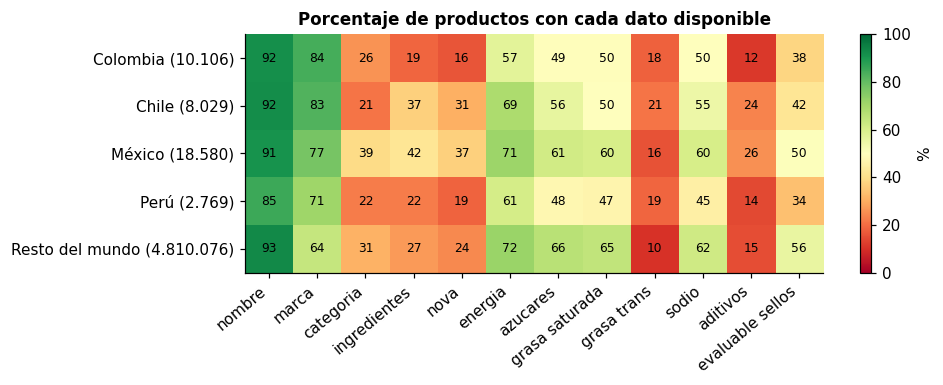

In [4]:
cob = pd.read_csv(IND / "cobertura_por_pais.csv").set_index("pais_grupo").loc[ORDEN]
cols = [c for c in cob.columns if c.startswith("pct_")]
etiquetas = {c: c.replace("pct_", "").replace("_", " ") for c in cols}
fig, ax = plt.subplots(figsize=(9, 3.6))
datos = cob[cols].rename(columns=etiquetas).rename(index=NOMBRE)
im = ax.imshow(datos.values, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(datos.columns)), datos.columns, rotation=40, ha="right")
ax.set_yticks(range(len(datos.index)), [f"{p} ({n:,})".replace(",", ".") for p, n in zip(datos.index, cob["productos"])])
for i in range(datos.shape[0]):
    for j in range(datos.shape[1]):
        ax.text(j, i, f"{datos.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
ax.set_title("Porcentaje de productos con cada dato disponible")
fig.colorbar(im, ax=ax, label="%")
guardar(fig, "01_completitud")

**Interpretación.** Colombia tiene 10.106 productos, pero es el país con **peor cobertura de ingredientes (19 %) y de NOVA (16 %)** entre los comparados, aunque sus marcas están mejor registradas (84 %). Solo el 38 % de los productos colombianos tiene los cuatro datos para evaluar sellos (energía, azúcares, grasa saturada y sodio): quedan 3.754 productos evaluables a los que aplica la norma, y 1.560 con ingredientes y NOVA para evaluar el modelo. La grasa trans casi nunca se reporta (18 %), por lo que ese sello está subestimado. Esta es la medición que pidió la retroalimentación del anteproyecto; con ella se ajustaron las metas.

## 3. ¿Cuántos productos hay por país?

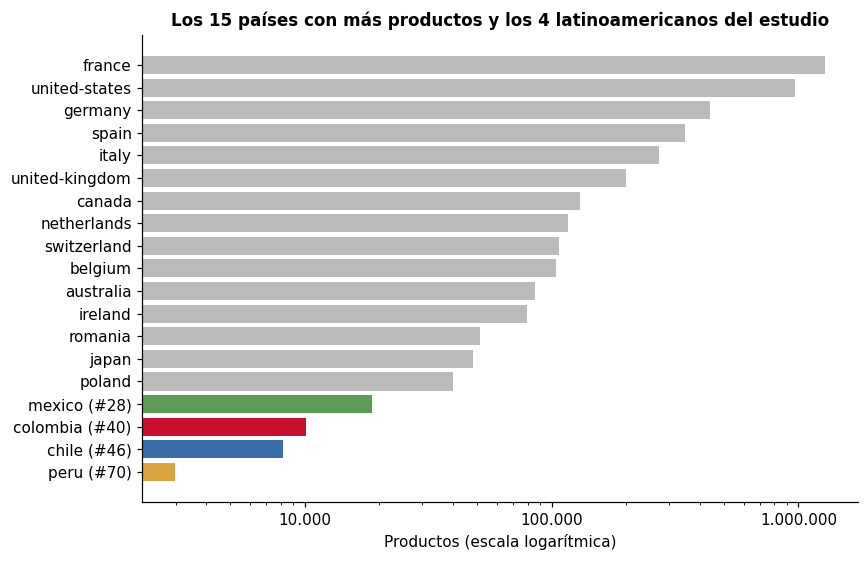

colombia: puesto 40. 10.106 productos
chile: puesto 46. 8.143 productos
mexico: puesto 28. 18.700 productos
peru: puesto 70. 2.982 productos


In [5]:
rank = (gold.select(F.explode("paises").alias("pais")).groupBy("pais").count()
        .filter("pais != 'en:world'")  # "world" es una etiqueta, no un país
        .orderBy(F.desc("count")).toPandas().reset_index(drop=True))
rank["puesto"] = rank.index + 1
rank["pais"] = rank["pais"].str.replace("en:", "")
latam = ["colombia", "chile", "mexico", "peru"]
tabla = pd.concat([rank.head(15), rank[rank.pais.isin(latam)]]).drop_duplicates("pais")
etiquetas = [f"{p} (#{n})" if p in latam else p for p, n in zip(tabla.pais, tabla.puesto)]
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(etiquetas[::-1], tabla["count"][::-1], color=[COLOR.get(p, "#BBBBBB") for p in tabla.pais][::-1])
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
ax.set_xlabel("Productos (escala logarítmica)")
ax.set_title("Los 15 países con más productos y los 4 latinoamericanos del estudio")
guardar(fig, "02_productos_por_pais")
for p in latam:
    f = rank[rank.pais == p].iloc[0]
    print(f"{p}: puesto {f.puesto}, {f['count']:,} productos".replace(",", "."))

**Interpretación.** La base está dominada por Europa y Estados Unidos (Francia sola aporta cerca de 1,3 millones de productos). Colombia ocupa el puesto 40 con 10.106 productos, por debajo de México (28.º) y por encima de Chile (46.º) y Perú (70.º). Por esta razón el modelo de procesamiento se entrena con productos de todo el mundo y Colombia se evalúa aparte.

## 4. Nivel de procesamiento (NOVA) por país

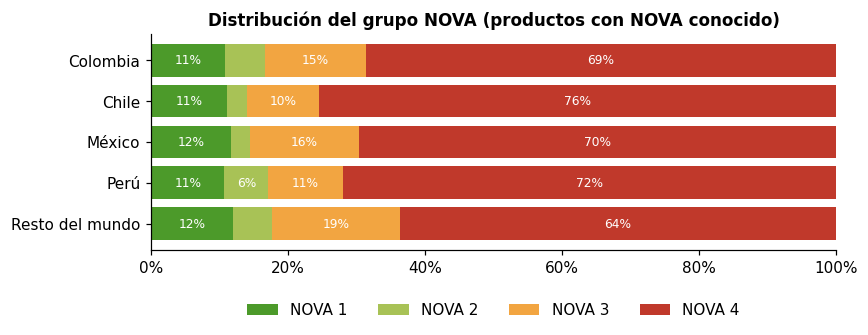

In [6]:
nova = pd.read_csv(IND / "nova_por_pais.csv").pivot(index="pais_grupo", columns="nova_group", values="pct").loc[ORDEN]
fig, ax = plt.subplots(figsize=(8, 3.4))
colores_nova = {1: "#4C9A2A", 2: "#A8C256", 3: "#F2A541", 4: "#C0392B"}
izq = pd.Series(0.0, index=nova.index)
for g in [1, 2, 3, 4]:
    ax.barh([NOMBRE[p] for p in nova.index], nova[g], left=izq, color=colores_nova[g], label=f"NOVA {g}")
    for i, (v, l) in enumerate(zip(nova[g], izq)):
        if v > 6: ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=8)
    izq += nova[g]
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.38), frameon=False)
ax.set_title("Distribución del grupo NOVA (productos con NOVA conocido)")
guardar(fig, "03_nova_por_pais")

**Interpretación.** En todos los grupos predominan los ultraprocesados (NOVA 4): en Colombia son el 69 % de los productos con NOVA conocido, similar a México (70 %), algo menos que Chile (76 %) y Perú (72 %) y más que el resto del mundo (64 %). Precaución: el NOVA solo se conoce para el 16 % de los productos colombianos (1.641) y los productos que registra la comunidad no son una muestra aleatoria del mercado (hay sesgo hacia productos empacados de marca).

## 5. Sellos de advertencia estimados por país

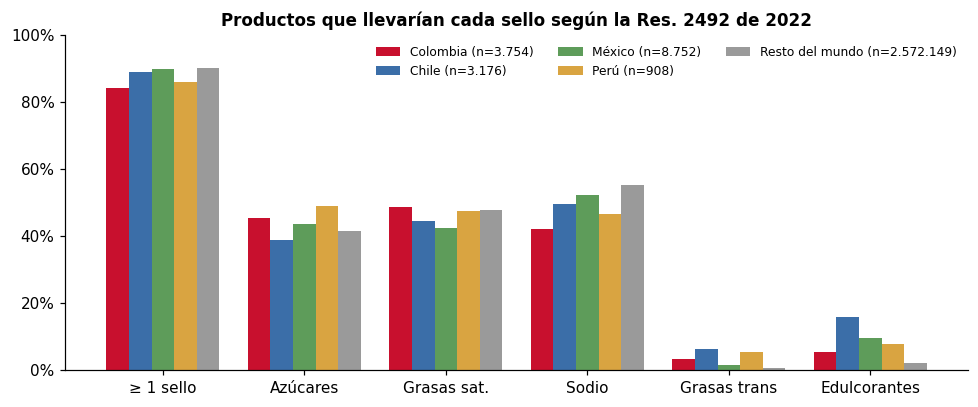

,productos,pct_con_algun_sello,pct_azucares,pct_grasas_saturadas,pct_sodio,pct_grasas_trans,pct_edulcorantes
pais_grupo,,,,,,,
colombia,3754,84.0,45.5,48.7,42.2,3.5,5.6
chile,3176,89.0,38.8,44.4,49.5,6.2,15.9
mexico,8752,89.9,43.6,42.5,52.1,1.7,9.5
peru,908,85.8,49.1,47.4,46.6,5.5,7.9
otros,2572149,90.2,41.5,47.8,55.2,0.7,2.2


In [7]:
sp = pd.read_csv(IND / "sellos_por_pais.csv").set_index("pais_grupo").loc[ORDEN]
sellos = {"pct_con_algun_sello": "≥ 1 sello", "pct_azucares": "Azúcares", "pct_grasas_saturadas": "Grasas sat.",
          "pct_sodio": "Sodio", "pct_grasas_trans": "Grasas trans", "pct_edulcorantes": "Edulcorantes"}
fig, ax = plt.subplots(figsize=(9, 3.8))
ancho = 0.16
for i, p in enumerate(ORDEN):
    x = [j + (i - 2) * ancho for j in range(len(sellos))]
    ax.bar(x, sp.loc[p, list(sellos)], ancho, color=COLOR[p], label=f"{NOMBRE[p]} (n={sp.loc[p, 'productos']:,})".replace(",", "."))
ax.set_xticks(range(len(sellos)), sellos.values())
ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_ylim(0, 100)
ax.legend(fontsize=8, frameon=False, ncol=3)
ax.set_title("Productos que llevarían cada sello según la Res. 2492 de 2022")
guardar(fig, "04_sellos_por_pais")
sp[["productos"] + list(sellos)]

**Interpretación.** Según la estimación, el **84 % de los productos colombianos evaluables llevaría al menos un sello**; los más frecuentes serían grasas saturadas (49 %), azúcares (46 %) y sodio (42 %). Los porcentajes son parecidos entre países porque se aplica la misma regla a todos. Chile destaca en edulcorantes (16 %), lo que podría reflejar la reformulación de productos tras su ley de etiquetado (queda por verificar). Estas cifras **probablemente sobreestiman** la realidad: la norma aplica solo a productos con azúcares, sodio o grasas añadidos, y eso no se puede verificar cuando faltan los ingredientes (81 % de los productos colombianos). La validación con 30 empaques fotografiados medirá este sesgo.

## 6. Colombia: ¿cuántos sellos lleva cada producto?

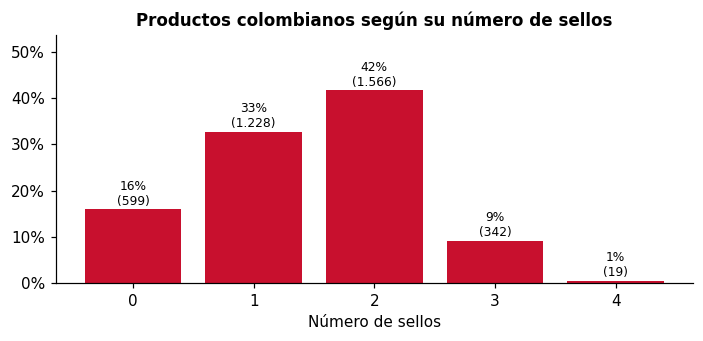

In [8]:
ns = pd.read_csv(IND / "colombia_numero_de_sellos.csv")
ns["pct"] = ns["count"] / ns["count"].sum() * 100
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.bar(ns["n_sellos"].astype(str), ns["pct"], color="#C8102E")
for x, (v, n) in enumerate(zip(ns["pct"], ns["count"])):
    ax.text(x, v + 1, f"{v:.0f}%\n({n:,})".replace(",", "."), ha="center", fontsize=8)
ax.set_xlabel("Número de sellos"); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(0, ns["pct"].max() + 12)
ax.set_title("Productos colombianos según su número de sellos")
guardar(fig, "05_colombia_numero_sellos")

**Interpretación.** La mayoría de productos colombianos evaluables tendría 1 sello (33 %) o 2 sellos (42 %); el 16 % no tendría ninguno, el 9 % tendría 3 y solo 19 productos llegarían a 4.

## 7. Colombia: sellos por categoría y por marca

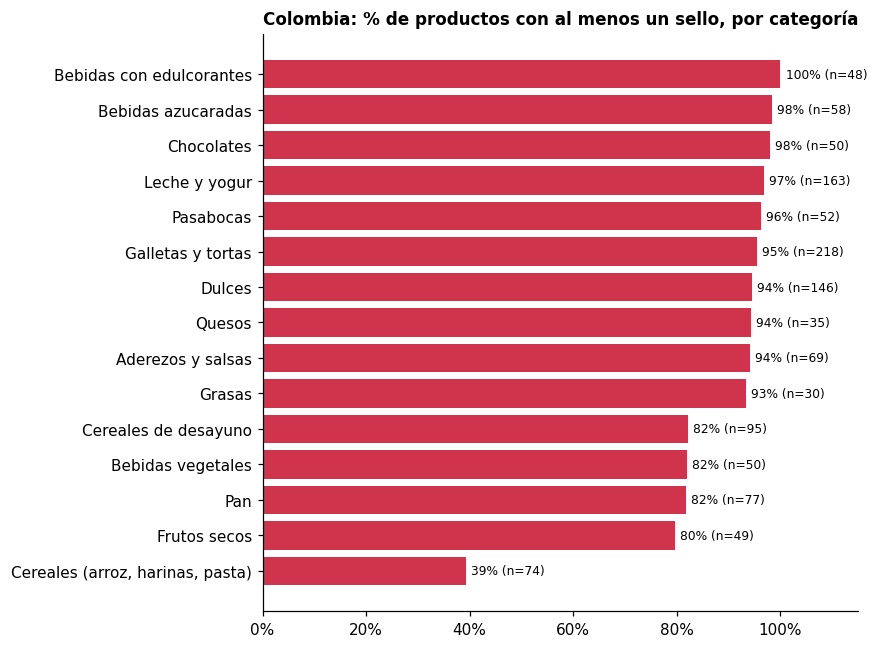

,categoria,productos,pct_con_algun_sello,sellos_promedio,pct_azucares,pct_grasas_saturadas,pct_grasas_trans,pct_sodio,pct_edulcorantes,pct_nova4
5,"Cereales (arroz, harinas, pasta)",74,39.2,0.65,13.5,17.6,0.0,29.7,4.1,36.5
11,Frutos secos,49,79.6,1.31,24.5,49.0,0.0,55.1,2.0,30.6
4,Pan,77,81.8,1.29,32.5,19.5,1.3,71.4,3.9,45.5
10,Bebidas vegetales,50,82.0,1.54,52.0,40.0,0.0,44.0,18.0,64.0
3,Cereales de desayuno,95,82.1,1.27,73.7,12.6,0.0,30.5,10.5,28.4
14,Grasas,30,93.3,1.10,0.0,93.3,0.0,16.7,0.0,13.3
6,Aderezos y salsas,69,94.2,1.74,50.7,37.7,1.4,82.6,1.4,59.4
13,Quesos,35,94.3,1.91,2.9,91.4,17.1,80.0,0.0,20.0
2,Dulces,146,94.5,1.53,84.9,43.8,1.4,11.0,12.3,50.7
0,Galletas y tortas,218,95.4,1.93,67.0,71.1,1.4,37.2,16.5,59.6


In [9]:
CATEGORIA_ES = {
    "Biscuits and cakes": "Galletas y tortas", "Milk and yogurt": "Leche y yogur", "Sweets": "Dulces",
    "Breakfast cereals": "Cereales de desayuno", "Bread": "Pan", "Cereals": "Cereales (arroz, harinas, pasta)",
    "Dressings and sauces": "Aderezos y salsas", "Sweetened beverages": "Bebidas azucaradas",
    "Appetizers": "Pasabocas", "Chocolate products": "Chocolates", "Plant-based milk substitutes": "Bebidas vegetales",
    "Nuts": "Frutos secos", "Artificially sweetened beverages": "Bebidas con edulcorantes", "Cheese": "Quesos",
    "Fats": "Grasas", "Fish and seafood": "Pescados y mariscos", "Processed meat": "Carnes procesadas",
    "Legumes": "Leguminosas", "Dried fruits": "Frutas deshidratadas", "Eggs": "Huevos"}
def barras_grupo(archivo, columna, titulo, nombre, top=15):
    t = pd.read_csv(IND / archivo).sort_values("productos", ascending=False).head(top)
    t[columna] = t[columna].replace(CATEGORIA_ES)
    t = t.sort_values("pct_con_algun_sello")
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(t) + 1.2))
    ax.barh(t[columna].str.replace("-", " "), t["pct_con_algun_sello"], color="#C8102E", alpha=0.85)
    for y, (v, n) in enumerate(zip(t["pct_con_algun_sello"], t["productos"])):
        ax.text(v + 1, y, f"{v:.0f}% (n={n})", va="center", fontsize=8)
    ax.set_xlim(0, 115); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title(titulo); guardar(fig, nombre)
    return t
barras_grupo("sellos_colombia_por_categoria.csv", "categoria",
             "Colombia: % de productos con al menos un sello, por categoría", "06_colombia_categoria")

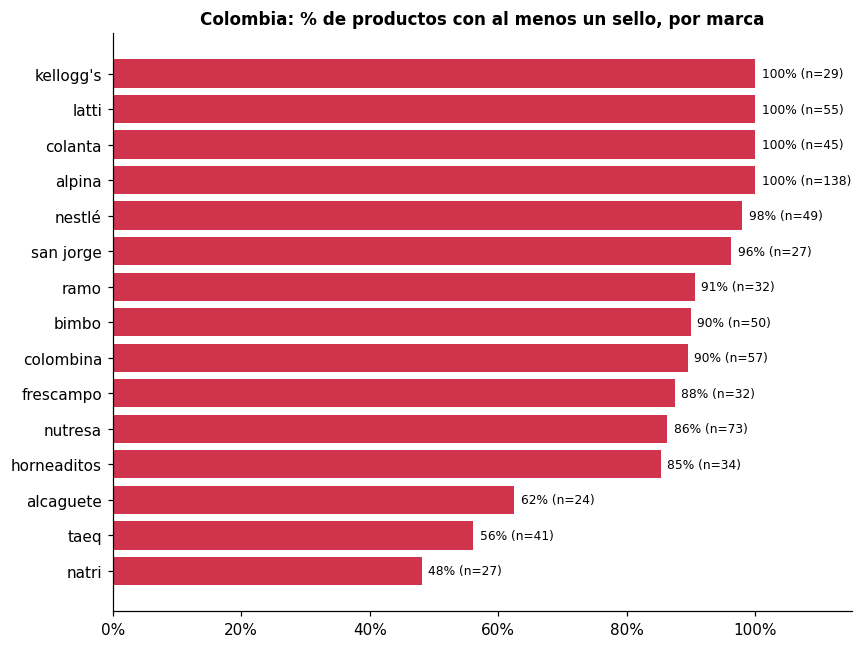

,marca,productos,pct_con_algun_sello,sellos_promedio,pct_azucares,pct_grasas_saturadas,pct_grasas_trans,pct_sodio,pct_edulcorantes,pct_nova4
13,natri,27,48.1,0.70,14.8,22.2,0.0,18.5,14.8,33.3
7,taeq,41,56.1,0.80,29.3,22.0,4.9,17.1,7.3,7.3
14,alcaguete,24,62.5,1.04,25.0,29.2,0.0,29.2,20.8,62.5
8,horneaditos,34,85.3,1.35,41.2,32.4,0.0,61.8,0.0,29.4
1,nutresa,73,86.3,1.64,57.5,61.6,0.0,32.9,12.3,53.4
10,frescampo,32,87.5,1.44,37.5,46.9,3.1,56.3,0.0,9.4
2,colombina,57,89.5,1.61,78.9,64.9,0.0,15.8,1.8,35.1
4,bimbo,50,90.0,1.40,52.0,28.0,0.0,58.0,2.0,26.0
9,ramo,32,90.6,1.81,68.8,78.1,3.1,31.3,0.0,28.1
12,san jorge,27,96.3,1.67,66.7,22.2,0.0,77.8,0.0,11.1


In [10]:
barras_grupo("sellos_colombia_por_marca.csv", "marca",
             "Colombia: % de productos con al menos un sello, por marca", "07_colombia_marca")

**Interpretación.** Por categoría, las bebidas endulzadas (con azúcar o con edulcorantes), los chocolates, la leche y el yogur y las galletas superan el 95 %, mientras que los cereales básicos (arroz, harinas, pastas) se quedan en 39 %: el motor sí distingue productos básicos de procesados. Leche y yogur aparecen altos sobre todo por grasas saturadas (78 %). Por marca, las grandes lácteas (Alpina, Colanta, Latti) aparecen con 100 % y las marcas de línea saludable (Taeq, Natri) quedan por debajo del 60 %. **Advertencia:** son estimaciones con pocos productos por marca (20 a 138) y datos colaborativos; no son una evaluación oficial de cumplimiento.

## 8. ¿Los ultraprocesados llevan más sellos?

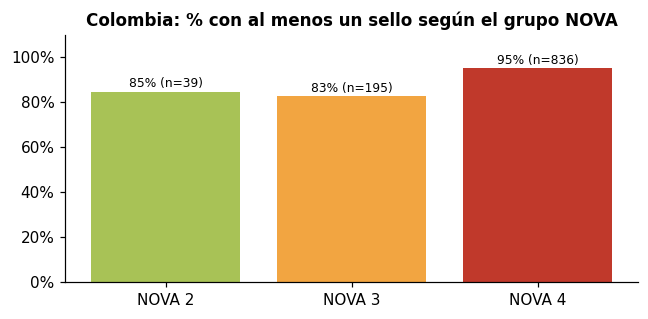

In [11]:
sn = pd.read_csv(IND / "colombia_sellos_por_nova.csv")
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar("NOVA " + sn["nova_group"].astype(str), sn["pct_con_algun_sello"],
       color=[colores_nova[g] for g in sn["nova_group"]])
for x, (v, n) in enumerate(zip(sn["pct_con_algun_sello"], sn["productos"])):
    ax.text(x, v + 2, f"{v:.0f}% (n={n})", ha="center", fontsize=8)
ax.set_ylim(0, 110); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Colombia: % con al menos un sello según el grupo NOVA")
guardar(fig, "08_colombia_sellos_vs_nova")

**Interpretación.** Procesamiento y sellos están relacionados: el 95 % de los ultraprocesados (NOVA 4) evaluables tendría al menos un sello, frente al 83 % de los NOVA 3 y el 85 % de los NOVA 2 (solo 39 productos: azúcar, aceites, sal, que por definición exceden algún nutriente). Los NOVA 1 no aparecen porque la norma no aplica a alimentos sin procesar. Solo 1.070 de los 3.754 productos evaluables tienen NOVA conocido.

## 9. Distribución de azúcares y sodio por grupo NOVA (mundo)

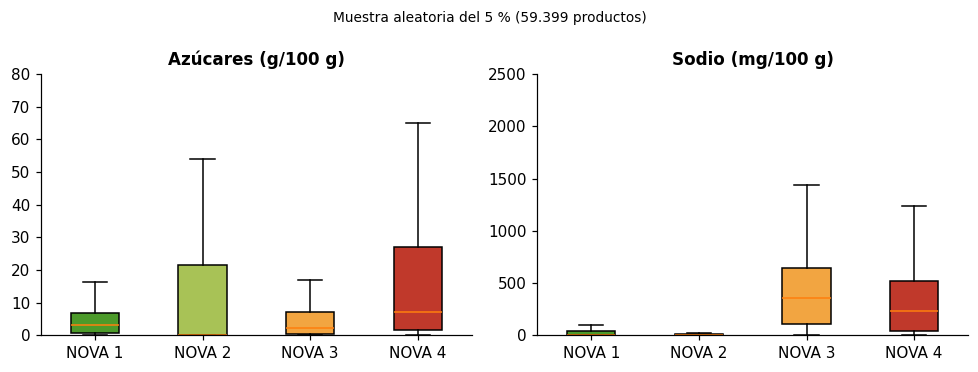

In [12]:
muestra = (gold.filter("nova_group IS NOT NULL").select("nova_group", "sugars_100g", "sodio_mg_100g")
           .sample(0.05, seed=42).toPandas())
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, (col, titulo, lim) in zip(axes, [("sugars_100g", "Azúcares (g/100 g)", 80), ("sodio_mg_100g", "Sodio (mg/100 g)", 2500)]):
    datos = [muestra.loc[muestra.nova_group == g, col].dropna() for g in [1, 2, 3, 4]]
    b = ax.boxplot(datos, tick_labels=[f"NOVA {g}" for g in [1, 2, 3, 4]], showfliers=False, patch_artist=True)
    for caja, g in zip(b["boxes"], [1, 2, 3, 4]): caja.set_facecolor(colores_nova[g])
    ax.set_title(titulo); ax.set_ylim(0, lim)
fig.suptitle(f"Muestra aleatoria del 5 % ({len(muestra):,} productos)".replace(",", "."), fontsize=9)
guardar(fig, "09_nutrientes_por_nova")

**Interpretación.** En la muestra mundial, los NOVA 4 tienen la mediana de azúcares más alta (≈ 7 g/100 g) y gran dispersión (hasta ≈ 65 g), mientras que los NOVA 3 (procesados: quesos, panes, conservas) concentran el sodio más alto (mediana ≈ 360 mg/100 g). Los NOVA 2 son ingredientes culinarios (azúcar, aceites, sal) con valores extremos. Conclusión: el procesamiento y el exceso de nutrientes están relacionados pero **no son lo mismo**; por eso el proyecto estima ambos por separado.

## Conclusiones del EDA

1. El flujo de big data procesa el volcado completo (4,92 M de productos, 14 GB) en unos 9 minutos en un equipo personal: bronce 4 min, plata 3 min y oro 2 min.
2. **Colombia está subrepresentada y con datos incompletos**: 10.106 productos, pero solo 19 % con ingredientes y 16 % con NOVA. Las metas se ajustaron a ese volumen (3.754 productos evaluables para sellos y 1.560 para el modelo).
3. Siete de cada diez productos colombianos con NOVA conocido son ultraprocesados, y el 84 % de los evaluables llevaría al menos un sello. Esta última cifra está probablemente sobreestimada y se validará con empaques reales.
4. Las categorías con más sellos son bebidas endulzadas, chocolates, lácteos y galletas; los cereales básicos tienen muchos menos.

In [13]:
spark.stop()